In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
import os
from scipy.interpolate import InterpolatedUnivariateSpline as inspl

## Notepad para graficación básica de datos (tstability)

In [2]:
# Leyendo archivos de datos
hu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\hu_tstability.dat')
zhang = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\zhang_tstability')
wu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\wu_tstability')
schmidt = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\schmidt_tstability2')

In [3]:
# Transformando
hu = np.transpose(hu)
zhang = np.transpose(zhang)
wu = np.transpose(wu)
schmidt = np.transpose(schmidt)

In [4]:
# Raspa min volume (1atm, 0Pa)
raspa_hu = 39278.1886848084
raspa_zhang = 39503.1530898870
raspa_wu = 39140.1101539154 #Not Completed Iteration 65
raspa_schmidt = 38220.7642612332

In [5]:
# Volume to Lparam
hu[1] = [0.5*((x)**(1/3)) for x in hu[1]]
zhang[1] = [0.5*((x)**(1/3)) for x in zhang[1]]
wu[1] = [0.5*((x)**(1/3)) for x in wu[1]]
schmidt[1] = [0.5*((x)**(1/3)) for x in schmidt[1]]
schmidt[1]

array([1.61761302, 1.61761302, 1.61831176, 1.61893041, 1.61948664,
       1.61995834, 1.62039644, 1.62073755])

In [6]:
# RASPA vol to Lparam
raspa_hu = 0.5*((raspa_hu)**(1/3))
raspa_zhang = 0.5*((raspa_zhang)**(1/3))
raspa_wu = 0.5*((raspa_wu)**(1/3))
raspa_schmidt = 0.5*((raspa_schmidt)**(1/3))

In [7]:
# Spline
where = 0
order = 1
spline = inspl(schmidt[0], schmidt[1], k=order)
sticks = np.linspace(0, 1010, 5000)
value0 = spline(where)
svals = spline(sticks)
print(value0)

1.6176130192156606


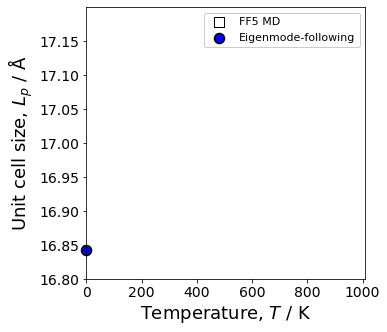

In [8]:
# Plotting FF
fig = plt.figure()
fig.set_size_inches(5.0, 5.0, forward=True)
plt.xlabel(r"Temperature, $T$ / $\mathrm{K}$", fontsize=18)
plt.ylabel(r"Unit cell size, $L_{p}$ / $\mathrm{\AA}$", fontsize=18)

plt.axis([0.0, 1010, 16.8, 17.2])
plt.xticks(np.arange(0.0, 1010, 200), fontsize=14)
plt.yticks(np.arange(16.8, 17.2, 0.05), fontsize=14)

# a[0], a[1], marker='o', color='red', edgecolor='black', linewidth=1, s=90, label='FF1', zorder=2
plt.scatter(schmidt[0], schmidt[1], marker='s', color='white', edgecolor='black', linewidth=1, s=100, zorder=2, label='FF5 MD')
plt.plot(sticks, svals, zorder=1, color='black', linewidth=1)
#plt.scatter(0, lammps_CG, clip_on=False, marker='s', color='red', edgecolor='black', linewidth=1.5, s=90, zorder=2, label='Serial CG w/box relax')
#plt.scatter(0, lammps_CG_2, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Serial CG w/box relax')
#plt.scatter(0, lammps_iter, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Alternating SD & CG w/box relax')
plt.scatter(0, raspa_schmidt, marker='o', clip_on=False, color='blue', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Eigenmode-following')
#plt.scatter(0, lammps_md, marker='s', clip_on=False, facecolors='none', edgecolor='red', linewidth=1.5, s=100, zorder=2)

plt.legend(facecolor='white', fontsize=11, framealpha=1)
# plt.grid(True, linestyle='--')
fig.savefig(r'C:\Users\20210015\Downloads\schmidt_min_spline.png', bbox_inches='tight', dpi=500)
#fig.savefig(r'C:\Users\Esteban\Downloads\zheng_min_spline.pdf', bbox_inches='tight')

plt.show()